# GAN 생성적 적대 신경망 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week15/gan/lab/gan.ipynb)

생성자 (위조범) 는 잡음 → 가짜, 판별자 (경찰) 는 그림 → 진짜일 확률. 번갈아 학습한다.

- **파트 1**: 손실 손 계산
- **파트 2**: 2차원 GAN: 봉우리 8개, 덮은 봉우리 수
- **파트 3**: 손글씨 숫자 GAN

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 · 3 은 1 ~ 2분씩 걸린다.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

## 파트 1. 손실

In [ ]:
def d_loss(d_real, d_fake):
    return -np.log(d_real) - np.log(1 - d_fake)          # discriminator: real -> 1, fake -> 0

def g_loss(d_fake):
    return None  # TODO: generator wants D(fake) -> 1

for d_real, d_fake in [(0.9, 0.2), (0.6, 0.6), (0.5, 0.5)]:
    print(f"D(real) = {d_real}, D(fake) = {d_fake}:  D loss {d_loss(d_real, d_fake):.2f},  G loss {g_loss(d_fake):.2f}")

**예상 결과**

```
D(real) = 0.9, D(fake) = 0.2:  D loss 0.33,  G loss 1.61
D(real) = 0.6, D(fake) = 0.6:  D loss 1.43,  G loss 0.51
D(real) = 0.5, D(fake) = 0.5:  D loss 1.39,  G loss 0.69
```

## 파트 2. 봉우리 8개

반지름 2 원 위 봉우리 8개 (표준편차 0.05). 생성자 · 판별자 모두 128칸 2층.

In [ ]:
bce = nn.BCEWithLogitsLoss()

def mlp(n_in, n_out, hidden=128, leaky=False, out=None):
    act = (lambda: nn.LeakyReLU(0.2)) if leaky else nn.ReLU
    layers = [nn.Linear(n_in, hidden), act(), nn.Linear(hidden, hidden), act(), nn.Linear(hidden, n_out)]
    return nn.Sequential(*(layers + ([out] if out else [])))

def train_gan(sample_real, z_dim, x_dim, steps, hidden=128, batch=256, out=None, seed=0, every=1000, check=None):
    torch.manual_seed(seed)
    G = mlp(z_dim, x_dim, hidden, out=out); D = mlp(x_dim, 1, hidden, leaky=True)
    opt_g = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    for step in range(steps + 1):
        if check and step % every == 0:
            with torch.no_grad():
                print(f"step {step}:", check(G(torch.randn(2000, z_dim)).numpy()))
        real = sample_real(batch); fake = G(torch.randn(batch, z_dim))
        loss_d = bce(D(real), torch.ones(batch, 1)) + bce(D(fake.detach()), torch.zeros(batch, 1))
        opt_d.zero_grad(); loss_d.backward(); opt_d.step()
        loss_g = None  # TODO: the generator wants D to say "real" (1) for fakes
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()
    return G, D

centers = torch.tensor([[2 * np.cos(2 * np.pi * k / 8), 2 * np.sin(2 * np.pi * k / 8)] for k in range(8)], dtype=torch.float32)

def eight_peaks(n):
    return centers[torch.randint(0, 8, (n,))] + 0.05 * torch.randn(n, 2)

def peaks_covered(x):
    d = np.linalg.norm(x[:, None, :] - centers.numpy()[None], axis=2)
    near, which = d.min(1) < 0.15, d.argmin(1)
    return f"{sum((which[near] == m).sum() >= 20 for m in range(8))} of 8 peaks"

G2, D2 = train_gan(eight_peaks, 2, 2, 3000, check=peaks_covered)
with torch.no_grad():
    fake = G2(torch.randn(1000, 2)).numpy()
    print("D(real) =", round(torch.sigmoid(D2(eight_peaks(2000))).mean().item(), 2), "  D(fake) =", round(torch.sigmoid(D2(G2(torch.randn(2000, 2)))).mean().item(), 2))
real = eight_peaks(1000).numpy()
plt.scatter(*real.T, s=4, c="gray", alpha=0.4); plt.scatter(*fake.T, s=4, c="red"); plt.gca().set_aspect("equal"); plt.show()

**예상 결과**

```
step 0: 0 of 8 peaks
step 1000: 4 of 8 peaks
step 2000: 8 of 8 peaks
step 3000: 8 of 8 peaks
D(real) = 0.54   D(fake) = 0.46
```

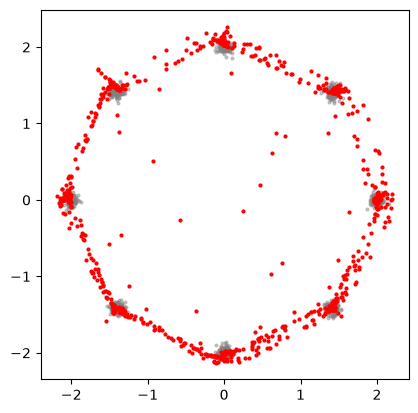

## 파트 3. 손글씨 숫자

생성자 16 → 256 → 256 → 64 (시그모이드). 뽑은 그림을 원본으로 학습한 분류기로 판정해 종류를 센다.

In [ ]:
digits = load_digits()
X = torch.tensor(digits.data / 16.0, dtype=torch.float32)
clf = LogisticRegression(max_iter=2000).fit(digits.data / 16.0, digits.target)

def sample_digits(n):
    return X[torch.randint(0, len(X), (n,))]

def kinds(x):
    counts = np.bincount(clf.predict(x), minlength=10)
    return f"{int((counts > 0).sum())} kinds, counts {counts.tolist()}"

G_dig, _ = train_gan(sample_digits, 16, 64, 10000, hidden=256, batch=128, out=nn.Sigmoid(), every=2000, check=kinds)
with torch.no_grad():
    pics = G_dig(torch.randn(16, 16)).numpy()
fig, axs = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, p in zip(axs.flat, pics):
    ax.imshow(p.reshape(8, 8), cmap="gray_r"); ax.axis("off")
plt.show()

**예상 결과**

```
step 0: 1 kinds, counts [0, 0, 0, 0, 2000, 0, 0, 0, 0, 0]
step 2000: 1 kinds, counts [0, 2000, 0, 0, 0, 0, 0, 0, 0, 0]
step 4000: 9 kinds, counts [396, 504, 194, 197, 0, 98, 33, 475, 97, 6]
step 6000: 10 kinds, counts [372, 129, 317, 149, 206, 4, 198, 1, 34, 590]
step 8000: 10 kinds, counts [61, 38, 12, 513, 234, 231, 39, 275, 384, 213]
step 10000: 10 kinds, counts [167, 193, 199, 327, 232, 176, 199, 105, 185, 217]
```

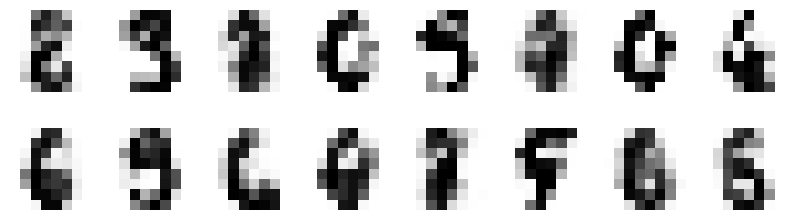

**확인 질문**
1. 파트 1 에서 판별자와 생성자의 손실이 함께 작아질 수 없는 이유는?
2. 파트 2 의 `seed` 를 바꿔 여러 번 학습해 보라. 언제나 8개 봉우리를 모두 덮는가?
3. 파트 3 에서 처음 몇천 걸음 동안 종류 수는 어떻게 변하나? 모드 붕괴가 보이는가?
4. (도전) 판별자의 학습률을 10배로 키우면 생성자는 어떻게 될까?